# 01 — Exploration et préparation de PAD-UFES-20

**Objectifs**
1. Vérifier l'intégrité du dataset (images ↔ CSV, doublons).
2. Créer la cible binaire : cancer (BCC, SCC, MEL) / non-cancer (ACK, NEV, SEK).
3. Analyser les valeurs manquantes et détecter les raccourcis.
4. Choisir les variables cliniques du modèle.
5. Découper les données par patient (test + 5 plis) et sauvegarder `data/processed/splits.csv`.

**Sorties** : `data/processed/splits.csv` et 3 figures dans `outputs/figures/`.

## 1. Imports et constantes

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "zr7vgbcyr2-1"
CSV_PATH = DATA_DIR / "metadata.csv"
IMG_DIR = DATA_DIR / "images"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "outputs" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

CANCER_CLASSES = {"BCC", "SCC", "MEL"}
print("Racine du projet :", ROOT)

Racine du projet : D:\Projetcs\Pfa-Project


## 2. Chargement et contrôles d'intégrité

Les valeurs `UNK` du CSV sont lues comme manquantes (`NaN`). Les images sont réparties dans 3 sous-dossiers : on construit un index `img_id → chemin`.

In [6]:
df = pd.read_csv(CSV_PATH, na_values=["UNK"])
print("Dimensions :", df.shape)
print("img_id dupliqués :", df["img_id"].duplicated().sum())
print("Patients :", df["patient_id"].nunique(), "| lésions (patient, lésion) :",
      df[["patient_id", "lesion_id"]].drop_duplicates().shape[0])

img_paths = {p.name: p for p in IMG_DIR.rglob("*.png")}
missing_imgs = set(df["img_id"]) - set(img_paths)
extra_imgs = set(img_paths) - set(df["img_id"])
print("Images trouvées :", len(img_paths), "| sans image :", len(missing_imgs),
      "| sans ligne CSV :", len(extra_imgs))
assert not missing_imgs and not extra_imgs, "incohérence entre images et CSV"

df["img_path"] = df["img_id"].map(lambda i: img_paths[i].relative_to(ROOT).as_posix())
print(df.iloc[11])

Dimensions : (2298, 26)
img_id dupliqués : 0
Patients : 1373 | lésions (patient, lésion) : 1891
Images trouvées : 2298 | sans image : 0 | sans ligne CSV : 0
patient_id                                                       PAT_967
lesion_id                                                           1827
smoke                                                              False
drink                                                              False
background_father                                              POMERANIA
background_mother                                              POMERANIA
age                                                                   34
pesticide                                                           True
gender                                                            FEMALE
skin_cancer_history                                                 True
cancer_history                                                     False
has_piped_water                         

## 3. Création de la cible binaire

In [3]:
df["label"] = df["diagnostic"].isin(CANCER_CLASSES).astype(int)
print(df["label"].value_counts())
print(pd.crosstab(df["diagnostic"], df["label"]))

label
0    1209
1    1089
Name: count, dtype: int64


label         0    1
diagnostic          
ACK         730    0
BCC           0  845
MEL           0   52
NEV         244    0
SCC           0  192
SEK         235    0


## 4. Distribution des classes

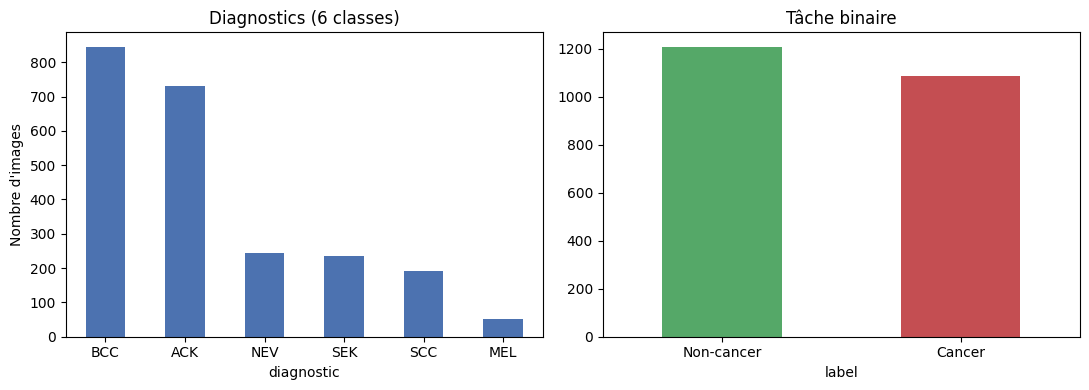

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["diagnostic"].value_counts().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Diagnostics (6 classes)")
axes[0].set_ylabel("Nombre d'images")
df["label"].map({0: "Non-cancer", 1: "Cancer"}).value_counts().plot.bar(
    ax=axes[1], color=["#55A868", "#C44E52"])
axes[1].set_title("Tâche binaire")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_distribution_classes.png", dpi=150)
plt.show()

## 5. Valeurs manquantes

In [5]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print((missing / len(df) * 100).round(1).astype(str) + " %")

background_father      39.7 %
background_mother      39.4 %
smoke                  35.0 %
drink                  35.0 %
pesticide              35.0 %
gender                 35.0 %
skin_cancer_history    35.0 %
cancer_history         35.0 %
has_piped_water        35.0 %
has_sewage_system      35.0 %
fitspatrick            35.0 %
diameter_1             35.0 %
diameter_2             35.0 %
grew                   17.5 %
changed                17.2 %
hurt                    0.4 %
itch                    0.3 %
bleed                   0.3 %
elevation               0.1 %
dtype: str


## 6. Détection d'un raccourci

Les 9 colonnes du profil patient sont vides sur les mêmes 804 lignes. On vérifie si cette absence dépend du diagnostic : si oui, le modèle pourrait prédire le cancer à partir du simple fait que le profil est vide.

In [6]:
PROFILE_COLS = ["smoke", "drink", "pesticide", "gender", "skin_cancer_history",
                "cancer_history", "fitspatrick", "diameter_1", "diameter_2"]
profile_missing = df[PROFILE_COLS].isna().any(axis=1)
print("Lignes sans profil :", profile_missing.sum())
print("Toutes les colonnes du profil vides ensemble :",
      (df[PROFILE_COLS].isna().all(axis=1) == profile_missing).all())

table = (df.assign(profile_missing=profile_missing)
           .groupby("diagnostic")["profile_missing"].mean().mul(100).round(1))
print("\n% de lignes sans profil par diagnostic :\n", table)

auc_shortcut = roc_auc_score(df["label"], (~profile_missing).astype(int))
print(f"\nAUC de la règle « profil complet => cancer » : {auc_shortcut:.3f}")

grew_missing = (df.groupby("diagnostic")["grew"]
                  .apply(lambda s: s.isna().mean() * 100).round(1))
print("\n% de `grew` manquant par diagnostic :\n", grew_missing)

Lignes sans profil : 804
Toutes les colonnes du profil vides ensemble : True

% de lignes sans profil par diagnostic :
 diagnostic
ACK    61.2
BCC     0.0
MEL     0.0
NEV    69.3
SCC     0.0
SEK    80.0
Name: profile_missing, dtype: float64

AUC de la règle « profil complet => cancer » : 0.833

% de `grew` manquant par diagnostic :
 diagnostic
ACK     0.8
BCC    31.5
MEL    21.2
NEV    14.8
SCC    39.1
SEK     3.4
Name: grew, dtype: float64


**Conclusion** : aucun cancer n'a un profil vide, contre 61 à 80 % des non-cancers. Une règle triviale atteint une AUC d'environ 0,83 sans regarder l'image : les variables du profil sont un **raccourci** et sont exclues du modèle. Pour la même raison, on ne crée pas d'indicateur de valeur manquante pour `grew` et `changed`.

## 7. Variables retenues et exclues

In [7]:
NUM_COLS = ["age"]
BOOL_COLS = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
CAT_COLS = ["region"]
FEATURES = NUM_COLS + BOOL_COLS + CAT_COLS

EXCLUDED = {
    "raccourci (profil manquant)": PROFILE_COLS,
    "fuite (révèle le diagnostic)": ["biopsed"],
    "faible intérêt clinique / biais social": ["has_piped_water", "has_sewage_system",
                                              "background_father", "background_mother"],
}
print("Variables retenues :", FEATURES)
for reason, cols in EXCLUDED.items():
    print(f"Exclues ({reason}) :", cols)

print("\nManquants restants dans les variables retenues :")
print(df[FEATURES].isna().sum()[lambda s: s > 0])

Variables retenues : ['age', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'region']
Exclues (raccourci (profil manquant)) : ['smoke', 'drink', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'fitspatrick', 'diameter_1', 'diameter_2']
Exclues (fuite (révèle le diagnostic)) : ['biopsed']
Exclues (faible intérêt clinique / biais social) : ['has_piped_water', 'has_sewage_system', 'background_father', 'background_mother']

Manquants restants dans les variables retenues :
itch           6
grew         402
hurt          10
changed      396
bleed          6
elevation      2
dtype: int64


Les quelques manquants restants (`grew`, `changed`, et quelques symptômes) seront imputés **au moment de l'entraînement**, avec des valeurs apprises sur chaque pli d'entraînement uniquement (`src/data/preprocessing.py`), pour éviter toute fuite.

## 8. Analyse des variables retenues

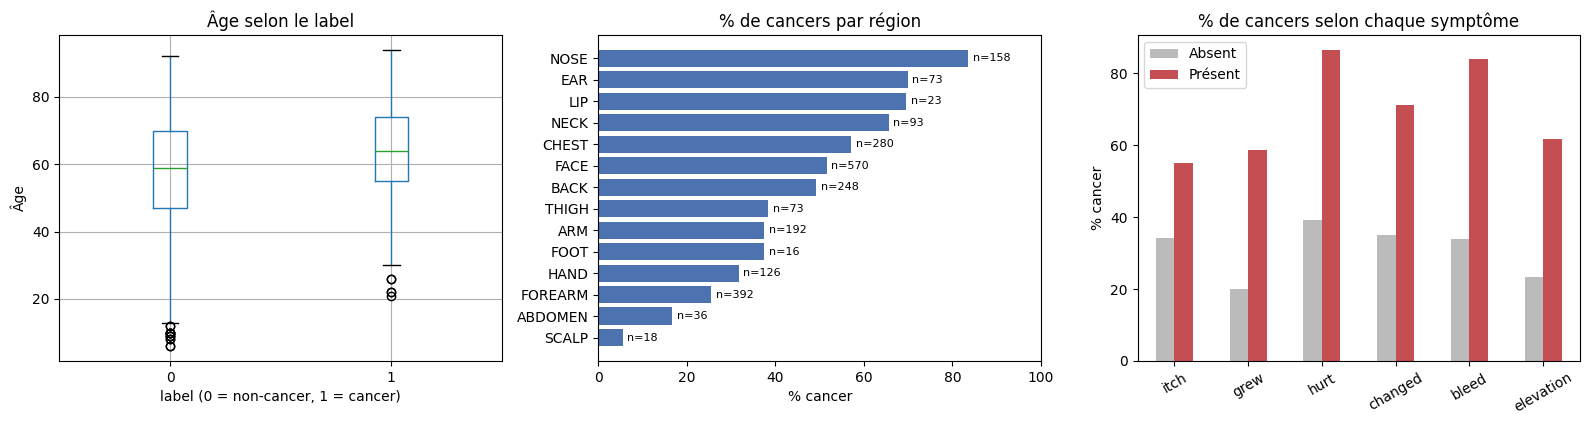

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df.boxplot(column="age", by="label", ax=axes[0])
axes[0].set_title("Âge selon le label")
axes[0].set_xlabel("label (0 = non-cancer, 1 = cancer)")
axes[0].set_ylabel("Âge")

region = df.groupby("region")["label"].agg(["mean", "size"]).sort_values("mean")
axes[1].barh(region.index, region["mean"] * 100, color="#4C72B0")
axes[1].set_title("% de cancers par région")
axes[1].set_xlabel("% cancer")
axes[1].set_xlim(0, 100)
for i, (pct, n) in enumerate(zip(region["mean"] * 100, region["size"])):
    axes[1].text(pct + 1, i, f"n={n}", va="center", fontsize=8)

sympt = pd.DataFrame({c: df.groupby(c)["label"].mean() * 100 for c in BOOL_COLS}).T
sympt = sympt.rename(columns={False: "Absent", True: "Présent"})
sympt[["Absent", "Présent"]].plot.bar(ax=axes[2], color=["#BBBBBB", "#C44E52"])
axes[2].set_title("% de cancers selon chaque symptôme")
axes[2].set_ylabel("% cancer")
axes[2].tick_params(axis="x", rotation=30)

plt.suptitle("")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_variables_retenues.png", dpi=150)
plt.show()

## 9. Contrôle des images

Modes couleur (échantillon de 300) : {'RGBA': 200, 'RGB': 100}
Taille min : (147, 147) | taille max : (2683, 2683) | tailles distinctes : 266


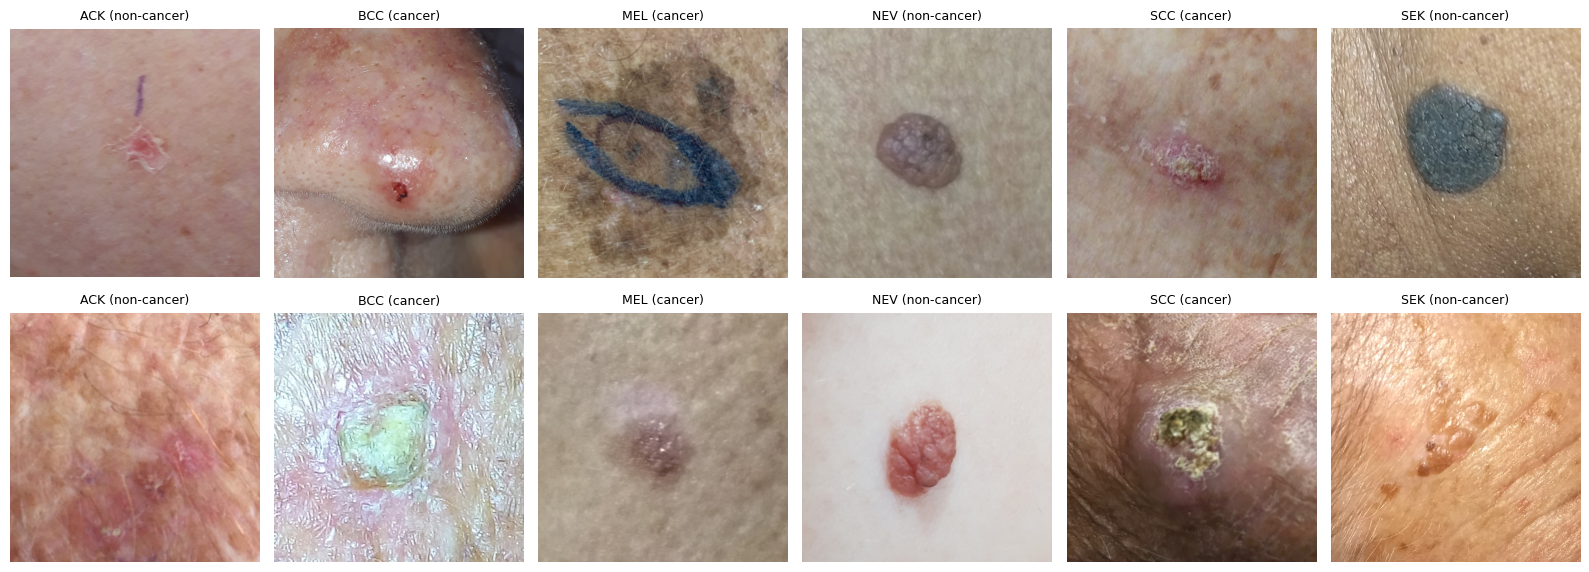

In [9]:
sample = df.sample(300, random_state=SEED)
sizes, modes = [], []
for p in sample["img_path"]:
    with Image.open(ROOT / p) as im:
        sizes.append(im.size)
        modes.append(im.mode)
sizes, modes = pd.Series(sizes), pd.Series(modes)
print("Modes couleur (échantillon de 300) :", modes.value_counts().to_dict())
print("Taille min :", min(sizes), "| taille max :", max(sizes),
      "| tailles distinctes :", sizes.nunique())

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for j, diag in enumerate(sorted(df["diagnostic"].unique())):
    rows = df[df["diagnostic"] == diag].sample(2, random_state=SEED)
    for i, (_, r) in enumerate(rows.iterrows()):
        ax = axes[i, j]
        with Image.open(ROOT / r["img_path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{diag} ({'cancer' if r['label'] else 'non-cancer'})", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_exemples_images.png", dpi=120)
plt.show()

**Conclusion** : une partie des images est en RGBA (4 canaux) et les tailles varient fortement. Le `Dataset` PyTorch devra convertir en RGB et redimensionner (224 × 224).

**Point de vigilance** : certaines lésions portent des **marques de stylo dermographique** (tracées avant une exérèse chirurgicale). Comme les lésions opérées sont souvent des cancers, le modèle pourrait apprendre à reconnaître l'encre plutôt que la lésion. À contrôler avec Grad-CAM (les cartes ne doivent pas se concentrer sur les traits d'encre) et en comparant les performances sur les images avec et sans marquage.

## 10. Découpage par patient

- Un ensemble de **test** (≈ 14 %) mis de côté jusqu'à l'évaluation finale.
- Le reste découpé en **5 plis** pour la validation croisée.
- Groupement par `patient_id` : aucun patient dans deux ensembles.
- Stratification sur les 6 diagnostics : les mélanomes (52 cas) sont présents partout.

In [13]:
df["split"] = "train"
df["fold"] = -1

outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
_, test_idx = next(outer.split(df, df["diagnostic"], groups=df["patient_id"]))
df.loc[test_idx, "split"] = "test"
print(df)
dev = df[df["split"] == "train"]
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, val_idx) in enumerate(inner.split(dev, dev["diagnostic"], groups=dev["patient_id"])):
    df.loc[dev.index[val_idx], "fold"] = k

     patient_id  lesion_id  smoke  drink background_father background_mother  \
0      PAT_1516       1765    NaN    NaN               NaN               NaN   
1        PAT_46        881  False  False         POMERANIA         POMERANIA   
2      PAT_1545       1867    NaN    NaN               NaN               NaN   
3      PAT_1989       4061    NaN    NaN               NaN               NaN   
4       PAT_684       1302  False   True         POMERANIA         POMERANIA   
...         ...        ...    ...    ...               ...               ...   
2293   PAT_1708       3156    NaN    NaN               NaN               NaN   
2294     PAT_46        880  False  False         POMERANIA         POMERANIA   
2295   PAT_1343       1217    NaN    NaN               NaN               NaN   
2296    PAT_326        690  False  False         POMERANIA         POMERANIA   
2297   PAT_1714       3189    NaN    NaN               NaN               NaN   

      age pesticide  gender skin_cancer

## 11. Vérifications du découpage

In [11]:
test_patients = set(df.loc[df["split"] == "test", "patient_id"])
dev_patients = set(df.loc[df["split"] == "train", "patient_id"])
assert not (test_patients & dev_patients), "patient commun entre test et train"

for k in range(5):
    p_k = set(df.loc[df["fold"] == k, "patient_id"])
    p_other = set(df.loc[(df["fold"] != k) & (df["split"] == "train"), "patient_id"])
    assert not (p_k & p_other), f"patient commun dans le pli {k}"
assert (df.loc[df["split"] == "train", "fold"] >= 0).all()
assert (df.loc[df["split"] == "test", "fold"] == -1).all()

groupe = np.where(df["split"] == "test", "test", "pli " + df["fold"].astype(str))
summary = (df.assign(groupe=groupe)
             .groupby("groupe")
             .agg(images=("img_id", "size"), patients=("patient_id", "nunique"),
                  pct_cancer=("label", lambda s: round(s.mean() * 100, 1))))
print(summary)
print(pd.crosstab(groupe, df["diagnostic"]))
print("OK : aucun patient commun entre test et plis, ni entre plis")

        images  patients  pct_cancer
groupe                              
pli 0      394       235        47.2
pli 1      393       236        47.6
pli 2      394       234        47.5
pli 3      394       235        47.5
pli 4      394       236        47.2
test       329       197        47.4
diagnostic  ACK  BCC  MEL  NEV  SCC  SEK
row_0                                   
pli 0       126  144    9   42   33   40
pli 1       125  145    9   41   33   40
pli 2       125  145    9   42   33   40
pli 3       125  145    9   42   33   40
pli 4       125  145    9   42   32   41
test        104  121    7   35   28   34
OK : aucun patient commun entre test et plis, ni entre plis


## 12. Sauvegarde

In [12]:
SPLIT_COLS = ["img_id", "patient_id", "lesion_id", "diagnostic", "label", "split", "fold", "img_path"]
df[SPLIT_COLS].to_csv(PROCESSED_DIR / "splits.csv", index=False)
print("Enregistré :", PROCESSED_DIR / "splits.csv", "|", len(df), "lignes")
pd.read_csv(PROCESSED_DIR / "splits.csv").head()

Enregistré : D:\Projetcs\Pfa-Project\data\processed\splits.csv | 2298 lignes


,img_id,patient_id,lesion_id,diagnostic,label,split,fold,img_path
0,PAT_1516_1765_530.png,PAT_1516,1765,NEV,0,test,-1,zr7vgbcyr2-1/images/imgs_part_3/imgs_part_3/PA...
1,PAT_46_881_939.png,PAT_46,881,BCC,1,train,3,zr7vgbcyr2-1/images/imgs_part_1/imgs_part_1/PA...
2,PAT_1545_1867_547.png,PAT_1545,1867,ACK,0,train,4,zr7vgbcyr2-1/images/imgs_part_3/imgs_part_3/PA...
3,PAT_1989_4061_934.png,PAT_1989,4061,ACK,0,train,1,zr7vgbcyr2-1/images/imgs_part_3/imgs_part_3/PA...
4,PAT_684_1302_588.png,PAT_684,1302,BCC,1,test,-1,zr7vgbcyr2-1/images/imgs_part_2/imgs_part_2/PA...


## Conclusion

- Dataset complet : 2 298 images, 1 373 patients, aucune image manquante.
- Cible binaire équilibrée : 1 089 cancers (47 %) / 1 209 non-cancers.
- Raccourci détecté : profil patient absent pour 0 % des cancers et 61–80 % des non-cancers (AUC ≈ 0,83 sans image) → variables du profil exclues.
- Variables retenues : âge, région, 6 symptômes (`itch`, `grew`, `hurt`, `changed`, `bleed`, `elevation`).
- Images : conversion RGB et redimensionnement nécessaires.
- Vigilance : marques de stylo sur certaines lésions, risque de second raccourci à vérifier avec Grad-CAM.
- `splits.csv` : un ensemble de test + 5 plis groupés par patient, réutilisés par tous les notebooks suivants.

**Étape suivante** : `02_baselines.ipynb`.